# Backpropagation Derivation

## Forward Propagation of a Two-Layer Neural Network

input 2개 → hidden neuron 2개 → output neuron 1개인 fully connected neural network를 다룬다. input layer를 제외하고, weight와 bias를 갖는 hidden layer와 output layer를 세어 **two-layer neural network**라고 부른다.

한 개의 input sample을 column vector로 표현하며, 이 예제에서는 hidden layer와 output layer 모두 Sigmoid activation function을 사용한다.

### Notation and Activation Function

- $x_1, x_2$: input
- $w_{ij}^{(l)}$: layer $(l-1)$의 $j$번째 neuron에서 layer $l$의 $i$번째 neuron으로 연결되는 weight
- $b_i^{(l)}$: layer $l$의 $i$번째 neuron의 bias
- $z_i^{(l)}$: activation function을 적용하기 전의 weighted sum
- $a_i^{(l)}$: activation function을 적용한 neuron의 output

weight matrix $W^{(l)}$의 **row는 도착 neuron**, **column은 출발 neuron**에 대응한다. 따라서 shape은 `(현재 layer의 neuron 수, 이전 layer의 neuron 수)`이다.

input 2개에서 hidden neuron 2개로 연결되는 weight는 다음과 같다.

$$
W^{(1)} = \begin{bmatrix}
w_{11}^{(1)} & w_{12}^{(1)} \\ 
w_{21}^{(1)} & w_{22}^{(1)}
\end{bmatrix},
\qquad \text{shape: }(2,2).
$$

첫 번째 row는 hidden neuron 1로 들어가는 두 weight이고, 두 번째 row는 hidden neuron 2로 들어가는 두 weight이다. 예를 들어 $w_{21}^{(1)}$은 input $x_1$에서 hidden neuron 2로 연결되는 weight이다.

hidden neuron 2개에서 output neuron 1개로 연결되는 weight는 한 row로 묶인다.

$$
W^{(2)} = \begin{bmatrix} w_{11}^{(2)} & w_{12}^{(2)} \end{bmatrix},
\qquad \text{shape: }(1,2).
$$

$w_{11}^{(2)}$과 $w_{12}^{(2)}$는 각각 hidden neuron 1과 2에서 동일한 output neuron으로 연결되는 weight이다.

input은 $\mathbf{a}^{(0)} = \mathbf{x}$로 두고, Sigmoid function은 다음과 같이 정의한다.

$$
\mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \end{bmatrix},
\qquad \sigma(t) = \frac{1}{1 + e^{-t}}.
$$

### Input Layer → Hidden Layer

각 hidden neuron은 두 input의 weighted sum에 bias를 더한 뒤 Sigmoid를 적용한다.

$$
\begin{aligned}
z_1^{(1)} &= w_{11}^{(1)} x_1 + w_{12}^{(1)} x_2 + b_1^{(1)}, \\ 
a_1^{(1)} &= \sigma\!\left(z_1^{(1)}\right), \\[4pt]
z_2^{(1)} &= w_{21}^{(1)} x_1 + w_{22}^{(1)} x_2 + b_2^{(1)}, \\ 
a_2^{(1)} &= \sigma\!\left(z_2^{(1)}\right).
\end{aligned}
$$

### Hidden Layer → Output Layer

output neuron은 두 hidden neuron의 output을 input으로 받아 prediction $\hat{y}$를 계산한다.

$$
\begin{aligned}
z_1^{(2)} &= w_{11}^{(2)} a_1^{(1)} + w_{12}^{(2)} a_2^{(1)} + b_1^{(2)}, \\ 
\hat{y} &= a_1^{(2)} = \sigma\!\left(z_1^{(2)}\right).
\end{aligned}
$$

### Matrix Form

각 layer의 weight와 bias를 다음과 같이 묶는다.

$$
W^{(1)} = \begin{bmatrix}
w_{11}^{(1)} & w_{12}^{(1)} \\ 
w_{21}^{(1)} & w_{22}^{(1)}
\end{bmatrix} \in \mathbb{R}^{2 \times 2},
\qquad
\mathbf{b}^{(1)} = \begin{bmatrix} b_1^{(1)} \\ b_2^{(1)} \end{bmatrix} \in \mathbb{R}^{2 \times 1}.
$$

$$
W^{(2)} = \begin{bmatrix} w_{11}^{(2)} & w_{12}^{(2)} \end{bmatrix} \in \mathbb{R}^{1 \times 2},
\qquad
\mathbf{b}^{(2)} = \begin{bmatrix} b_1^{(2)} \end{bmatrix} \in \mathbb{R}^{1 \times 1}.
$$

forward propagation은 다음 순서로 계산한다. vector에 대한 $\sigma$는 각 element에 독립적으로 적용한다.

$$
\begin{aligned}
\mathbf{z}^{(1)} &= W^{(1)} \mathbf{x} + \mathbf{b}^{(1)} \in \mathbb{R}^{2 \times 1}, \\ 
\mathbf{a}^{(1)} &= \sigma\!\left(\mathbf{z}^{(1)}\right) \in \mathbb{R}^{2 \times 1}, \\ 
\mathbf{z}^{(2)} &= W^{(2)} \mathbf{a}^{(1)} + \mathbf{b}^{(2)} \in \mathbb{R}^{1 \times 1}, \\ 
\mathbf{a}^{(2)} &= \sigma\!\left(\mathbf{z}^{(2)}\right) = \begin{bmatrix} \hat{y} \end{bmatrix} \in \mathbb{R}^{1 \times 1}.
\end{aligned}
$$

따라서 input에서 output까지의 계산을 하나의 equation으로 쓰면 다음과 같다.

$$
\boxed{\mathbf{a}^{(2)} = \sigma\!\left(W^{(2)} \sigma\!\left(W^{(1)} \mathbf{x} + \mathbf{b}^{(1)}\right) + \mathbf{b}^{(2)}\right)}
$$

## Forward Propagation by Hand

주어진 input `x = [1, 0]`과 bias `b1 = [0, 0]`는 앞 절과 같은 column vector로 표현하고, `W2 = [0.5, 0.6]`는 row vector로 표현한다.

| Name | Value | Shape / Type |
| --- | --- | --- |
| `x` | $\mathbf{x}=\begin{bmatrix}1 \\ 0\end{bmatrix}$ | $(2,1)$ |
| `W1` | $W^{(1)}=\begin{bmatrix}0.1 & 0.2 \\ 0.3 & 0.4\end{bmatrix}$ | $(2,2)$ |
| `b1` | $\mathbf{b}^{(1)}=\begin{bmatrix}0 \\ 0\end{bmatrix}$ | $(2,1)$ |
| `W2` | $W^{(2)}=\begin{bmatrix}0.5 & 0.6\end{bmatrix}$ | $(1,2)$ |
| `b2` | $b_1^{(2)}=0$ | scalar |
| `y_true` | $y=1$ | scalar |

두 layer의 activation function은 $\sigma(t)=1/(1+e^{-t})$인 Sigmoid이다. 중간값은 충분한 자릿수로 기록하고, 다음 계산에는 반올림 전 값을 사용한다. 마지막 표에서 각 결과를 소수점 4자리로 정리한다.

### Hidden Layer Weighted Sum: `z1`

두 hidden neuron의 weighted sum에 주어진 숫자를 대입한다.

$$
\begin{aligned}
z_1^{(1)}
&=0.1\times1+0.2\times0+0
=0.1, \\
z_2^{(1)}
&=0.3\times1+0.4\times0+0
=0.3.
\end{aligned}
$$

따라서 `z1`은 다음 column vector이다.

$$
\mathbf{z}^{(1)}=W^{(1)}\mathbf{x}+\mathbf{b}^{(1)}
=\begin{bmatrix}0.1 \\ 0.3\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

matrix multiplication의 shape은 $(2,2)\ @\ (2,1)\longrightarrow(2,1)$이고, 여기에 같은 shape의 bias를 더한다.

### Hidden Layer Activation: `a1`

각 hidden neuron의 weighted sum에 Sigmoid를 적용한다.

$$
\begin{aligned}
a_1^{(1)}
&=\sigma(0.1)
=\frac{1}{1+e^{-0.1}}
\approx0.5249791875, \\
a_2^{(1)}
&=\sigma(0.3)
=\frac{1}{1+e^{-0.3}}
\approx0.5744425168.
\end{aligned}
$$

따라서 `a1`은 다음 column vector이다. activation function은 element-wise로 적용되므로 shape이 유지된다.

$$
\mathbf{a}^{(1)}=\sigma\!\left(\mathbf{z}^{(1)}\right)
\approx\begin{bmatrix}0.5249791875 \\ 0.5744425168\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

### Output Layer Weighted Sum: `z2`

두 hidden neuron의 activation에 output layer의 weight를 곱하고 bias를 더한다.

$$
\begin{aligned}
z_1^{(2)}
&=0.5a_1^{(1)}+0.6a_2^{(1)}+0 \\
&=0.5\sigma(0.1)+0.6\sigma(0.3) \\
&\approx0.2624895937+0.3446655101 \\
&\approx0.6071551038.
\end{aligned}
$$

matrix multiplication $W^{(2)}\mathbf{a}^{(1)}$의 shape은 $(1,2)\ @\ (2,1)\longrightarrow(1,1)$이다. 이 절의 `z2`는 output array의 유일한 element인 $z_1^{(2)}$를 뜻하며 scalar이다.

### Prediction: `y_pred`

output layer의 weighted sum에 Sigmoid를 적용한다.

$$
\begin{aligned}
\hat{y}
&=\sigma\!\left(z_1^{(2)}\right)
=\frac{1}{1+e^{-z_1^{(2)}}} \\
&\approx\frac{1}{1+e^{-0.6071551038}} \\
&\approx0.6472915700.
\end{aligned}
$$

`y_pred`는 prediction $\hat{y}$를 뜻하며 scalar이다.

### BCE Loss: `y_true = 1`

target은 $y=1$이므로 BCE의 두 번째 term이 0이 되어 다음과 같이 계산한다.

$$
\begin{aligned}
L
&=-\left[1\cdot\log\hat{y}+(1-1)\log(1-\hat{y})\right] \\
&=-\log\hat{y} \\
&\approx-\log(0.6472915700) \\
&\approx0.4349584369.
\end{aligned}
$$

`loss`는 scalar이며, 소수점 4자리로 표시하면 $0.4350$이다.

### Forward Propagation Results

| Intermediate | Notation | Value (4 decimal places) | Shape / Type |
| --- | --- | --- | --- |
| `z1` | $\mathbf{z}^{(1)}$ | $\begin{bmatrix}0.1000 \\ 0.3000\end{bmatrix}$ | $(2,1)$ |
| `a1` | $\mathbf{a}^{(1)}$ | $\begin{bmatrix}0.5250 \\ 0.5744\end{bmatrix}$ | $(2,1)$ |
| `z2` | $z_1^{(2)}$ | $0.6072$ | scalar |
| `y_pred` | $\hat{y}$ | $0.6473$ | scalar |
| `loss` | $L=-\log\hat{y}$ | $0.4350$ | scalar |

이 표의 값은 최종 표시를 위해 반올림한 값이다. 예를 들어 `a1`을 먼저 소수점 4자리로 반올림해 다음 layer에 대입하면 `z2`의 소수점 4자리 결과가 달라질 수 있다.

## NumPy Verification

위 손계산과 같은 input, weight, bias로 forward propagation을 수행하고, `y_true = 1.0`으로 BCE loss를 계산한다. `x`, `b1`, `z1`, `a1`은 column vector로, `W2`는 row vector로 표현한다. `z2`와 `y_pred`는 scalar로 계산한다.

계산 도중에는 반올림하지 않고, 각 intermediate와 loss를 소수점 4자리로 반올림한 뒤 손계산 표의 값과 element-wise로 비교한다. 모든 값이 일치해야 assertion을 통과한다.

In [1]:
# Import NumPy for forward propagation, BCE loss, and gradient verification.

import numpy as np

In [2]:
# Define the input, weights, biases, and target from the worked example.

x = np.array([[1.0], [0.0]])
W1 = np.array([[0.1, 0.2], [0.3, 0.4]])
b1 = np.zeros((2, 1))
W2 = np.array([[0.5, 0.6]])
b2 = 0.0

y_true = 1.0

In [3]:
# Define the activation function used by both network layers.

# Apply Sigmoid element-wise to a scalar or array.
def sigmoid(value):
    return 1.0 / (1.0 + np.exp(-value))

In [4]:
# Compute every forward-propagation intermediate without rounding.

# (2, 2) @ (2, 1) + (2, 1) -> (2, 1).
z1 = W1 @ x + b1
a1 = sigmoid(z1)

# (1, 2) @ (2, 1) -> (1, 1); extract its sole element as a scalar.
z2 = (W2 @ a1).item() + b2
y_pred = sigmoid(z2)

In [5]:
# Calculate BCE loss for the specified target.

# log1p(-p) evaluates log(1 - p) without explicitly subtracting p from one.
loss = -(y_true * np.log(y_pred) + (1.0 - y_true) * np.log1p(-y_pred))

In [6]:
# Record the independent reference values from the four-decimal hand-calculation table.

hand_results = {
    "z1": np.array([[0.1000], [0.3000]]),
    "a1": np.array([[0.5250], [0.5744]]),
    "z2": 0.6072,
    "y_pred": 0.6473,
    "loss": 0.4350,
}

In [7]:
# Verify that forward intermediates and BCE loss match the hand calculations to four decimal places.

numpy_results = {"z1": z1, "a1": a1, "z2": z2, "y_pred": y_pred, "loss": loss}
for name, actual in numpy_results.items():
    expected = hand_results[name]
    rounded = np.round(actual, decimals=4)
    np.testing.assert_array_equal(
        rounded, expected, strict=True,
        err_msg=f"{name} does not match the hand calculation to 4 decimal places.",
    )
    if np.ndim(actual) == 0:
        print(f"{name} (scalar): hand={expected:.4f}, NumPy={actual:.4f} -> PASS")
    else:
        # Flatten only for display; the calculation and comparison retain column-vector shapes.
        hand_text = np.array2string(
            expected.ravel(), precision=4, floatmode="fixed", separator=", "
        )
        numpy_text = np.array2string(
            rounded.ravel(), precision=4, floatmode="fixed", separator=", "
        )
        print(f"{name} {actual.shape}: hand={hand_text}, NumPy={numpy_text} -> PASS")

print("All forward intermediates and BCE loss match the hand calculations to 4 decimal places.")

z1 (2, 1): hand=[0.1000, 0.3000], NumPy=[0.1000, 0.3000] -> PASS
a1 (2, 1): hand=[0.5250, 0.5744], NumPy=[0.5250, 0.5744] -> PASS
z2 (scalar): hand=0.6072, NumPy=0.6072 -> PASS
y_pred (scalar): hand=0.6473, NumPy=0.6473 -> PASS
loss (scalar): hand=0.4350, NumPy=0.4350 -> PASS
All forward intermediates and BCE loss match the hand calculations to 4 decimal places.


## Computational Graph

이번 예시의 input, parameter, intermediate, loss를 vector 단위의 computational graph로 표현한다. `Affine` node는 `MatMul`과 `Add`를 묶은 operation이며, 옆의 weight와 bias node도 해당 operation의 input이다.

### Forward Computational Graph

파란 실선 화살표를 위에서 아래로 따라가면 앞에서 계산한 `z1 → a1 → z2 → y_pred`를 얻는다. 숫자는 소수점 4자리로 표시하며, 실제 계산에는 반올림 전 값을 사용한다. target `y_true = 1`과 BCE loss $L\approx0.4350$도 표시했다. vector와 matrix에는 shape을, scalar에는 scalar임을 표시했다.

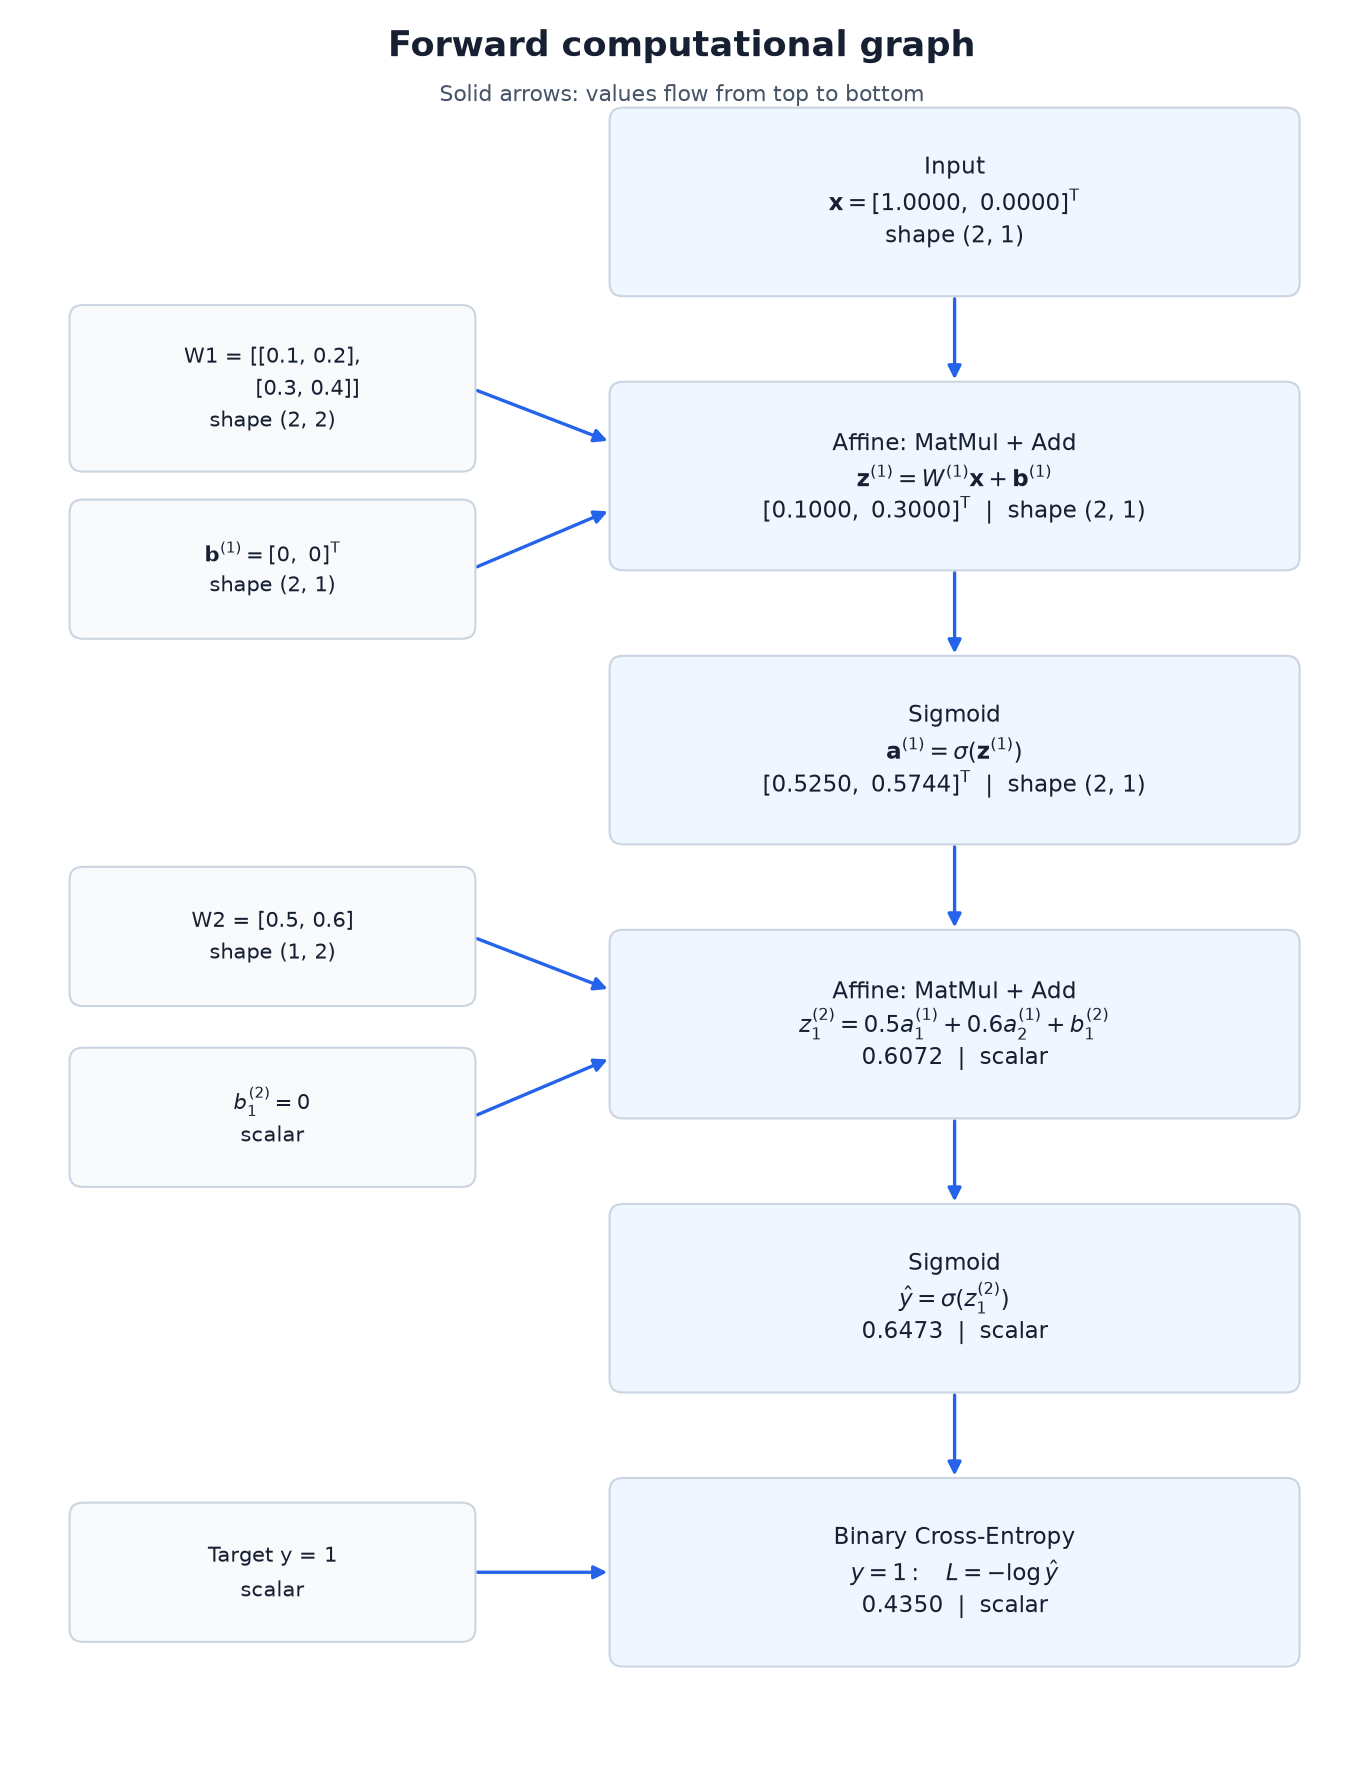

### Backward Gradient Flow

target $y=1$ (`y_true = 1.0`)을 constant로 취급한다. loss와 모든 backward gradient에 이번 예시의 숫자를 대입해 표시한다.

주황 점선 화살표는 같은 graph의 연결을 반대로 따라간다. 아래의 loss에서 $\partial L/\partial L=1$로 시작해 위쪽의 input과 옆의 parameter로 gradient를 전달한다. 그림의 $\delta^{(1)}$는 hidden layer의 vector gradient이고, $\delta_1^{(2)}$는 output layer의 scalar gradient이다.

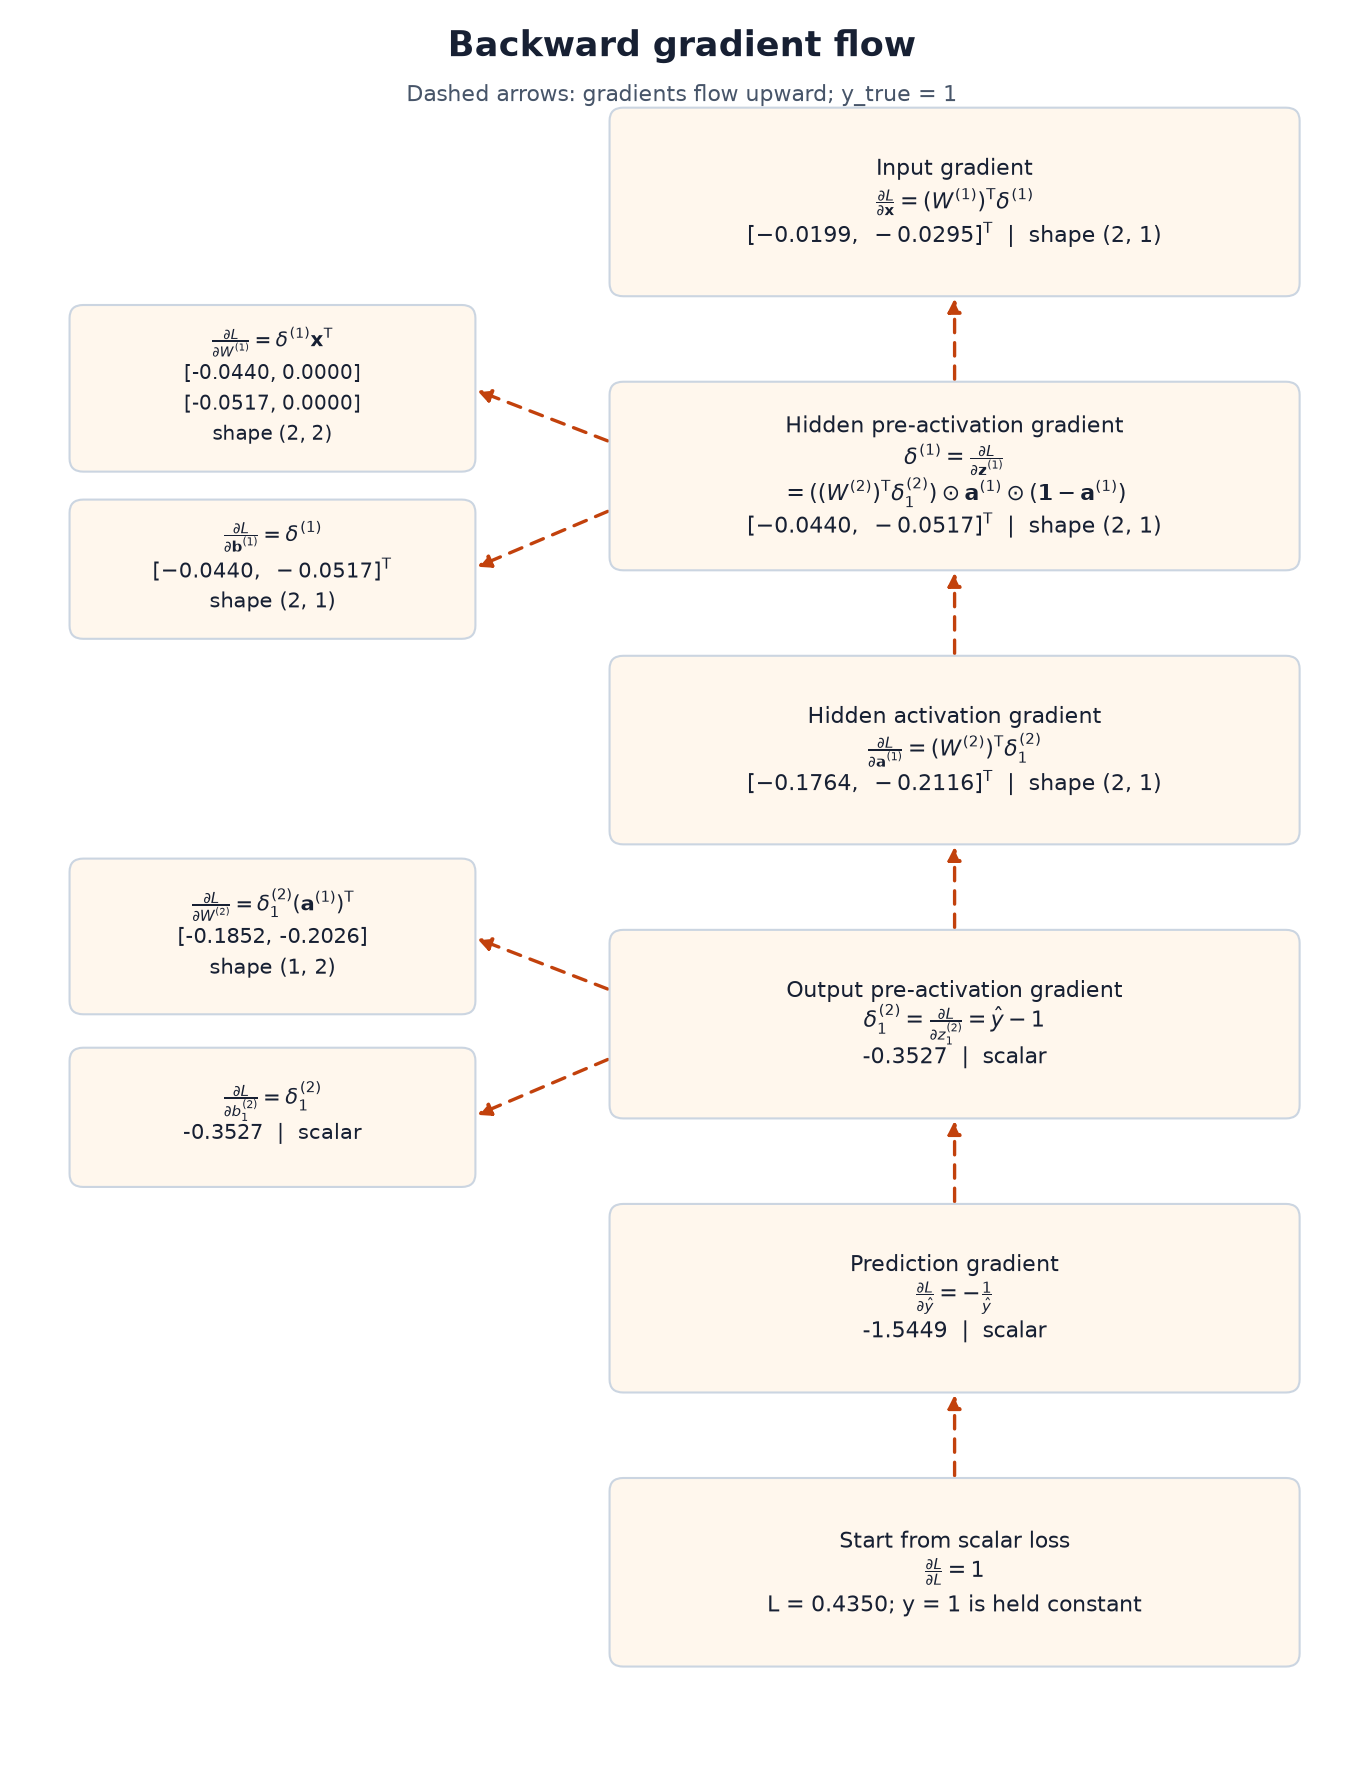

- 각 node에서는 전달받은 gradient에 해당 operation의 local derivative를 적용한다. Sigmoid에서는 element-wise product를, Affine에서는 transpose와 matrix multiplication을 사용한다.
- 옆으로 나가는 화살표는 weight와 bias에 대한 gradient이다. hidden layer의 weight gradient $\partial L/\partial W^{(1)}=\boldsymbol{\delta}^{(1)}\mathbf{x}^{\mathsf T}$가 앞서 유도한 outer product에 해당한다.
- vector node를 element 단위로 펼치면 input $x_j$가 두 hidden neuron으로 연결된다. 따라서 $\partial L/\partial x_j=\sum_{i=1}^{2}\delta_i^{(1)}w_{ij}^{(1)}$처럼 여러 경로의 기여를 더한다.

## Backpropagation Derivation Using the Chain Rule

앞 절과 같은 column vector 표기를 사용한다. 일반 BCE에서는 한 sample의 target이 $y \in \{0, 1\}$이고, 이번 예시에서는 $y=1$ (`y_true = 1.0`)로 고정한다. prediction을 $\hat{y}$라고 두고 Binary Cross-Entropy(BCE) loss를 정의한다. $\log$는 natural logarithm이며, Sigmoid output은 $0 < \hat{y} < 1$이다.

$$
L = -\left[y\log\hat{y} + (1-y)\log(1-\hat{y})\right].
$$

이번 예시에서는 $L=-\log\hat{y}\approx0.4349584369$이다. target $y=1$은 derivative를 구할 때 constant로 취급한다. 각 단계에서 일반 chain rule을 먼저 유도하고, 같은 식에 $y=1$과 앞서 구한 값을 대입한다. forward propagation의 중간값을 이용해 $L$에서 output layer, hidden layer, input 순서로 gradient를 전달한다.

| Notation | Meaning | Shape / Type |
| --- | --- | --- |
| $\mathbf{x}$ | input | $(2,1)$ |
| $W^{(1)}$ | input → hidden weights | $(2,2)$ |
| $\mathbf{b}^{(1)},\ \mathbf{z}^{(1)},\ \mathbf{a}^{(1)}$ | hidden layer bias, weighted sum, output | 각각 $(2,1)$ |
| $W^{(2)}$ | hidden → output weights | $(1,2)$ |
| $\mathbf{b}^{(2)},\ \mathbf{z}^{(2)},\ \mathbf{a}^{(2)}$ | output layer bias, weighted sum, output | 각각 $(1,1)$ |
| $z_1^{(2)},\ \hat{y}=a_1^{(2)},\ y,\ L$ | output layer elements, target, loss | 각각 scalar |

scalar loss의 array에 대한 gradient는 해당 array와 같은 shape으로 배치한다. 예를 들어 $\partial L/\partial W^{(1)}$의 $(i,j)$번째 element는 $\partial L/\partial w_{ij}^{(1)}$이다. $\odot$는 같은 shape을 갖는 array의 **element-wise product**를 나타낸다.

### 1단계. Loss → Prediction: $\partial L/\partial\hat{y}$

BCE의 두 term에 대해 각각 derivative를 구한다. 두 번째 term에서는 $\partial(1-\hat{y})/\partial\hat{y}=-1$이므로 sign이 한 번 더 바뀐다.

$$
\begin{aligned}
\frac{\partial L}{\partial\hat{y}}
&= -\frac{y}{\hat{y}} + \frac{1-y}{1-\hat{y}} \\
&= \frac{-y(1-\hat{y})+(1-y)\hat{y}}{\hat{y}(1-\hat{y})} \\
&= \boxed{\frac{\hat{y}-y}{\hat{y}(1-\hat{y})}}.
\end{aligned}
$$

$L$과 $\hat{y}$가 모두 scalar이므로 $\partial L/\partial\hat{y}$도 scalar이다.

이번 예시의 $y=1$을 대입하면 다음과 같다.

$$
\frac{\partial L}{\partial\hat{y}}
=-\frac{1}{\hat{y}}
\approx-1.5448988468.
$$

### 2단계. Prediction → Output Layer Weighted Sum: $\partial L/\partial z_1^{(2)}$

먼저 Sigmoid의 derivative를 구한다.

$$
\begin{aligned}
\sigma'(t)
&= \frac{e^{-t}}{(1+e^{-t})^2} \\
&= \frac{1}{1+e^{-t}}\left(1-\frac{1}{1+e^{-t}}\right) \\
&= \sigma(t)\left(1-\sigma(t)\right).
\end{aligned}
$$

$\hat{y}=\sigma(z_1^{(2)})$이므로 chain rule을 적용하면 다음과 같다.

$$
\begin{aligned}
\delta_1^{(2)}
:= \frac{\partial L}{\partial z_1^{(2)}}
&= \frac{\partial L}{\partial\hat{y}}\frac{\partial\hat{y}}{\partial z_1^{(2)}} \\
&= \frac{\hat{y}-y}{\hat{y}(1-\hat{y})}\,\hat{y}(1-\hat{y}) \\
&= \boxed{\hat{y}-y}.
\end{aligned}
$$

BCE와 Sigmoid를 함께 사용하면 denominator와 Sigmoid derivative의 공통 factor가 약분된다. $\delta_1^{(2)}$는 scalar이고, matrix 계산에서는 이를 다음과 같이 묶는다.

$$
\boldsymbol{\delta}^{(2)}
:= \frac{\partial L}{\partial\mathbf{z}^{(2)}}
= \begin{bmatrix}\hat{y}-y\end{bmatrix},
\qquad \text{shape: }(1,1).
$$

이번 예시에서는 다음과 같다.

$$
\delta_1^{(2)}=\hat{y}-1
\approx-0.3527084300,
\qquad
\boldsymbol{\delta}^{(2)}\approx\begin{bmatrix}-0.3527084300\end{bmatrix}.
$$

$\delta_1^{(2)}$는 scalar이고, $\boldsymbol{\delta}^{(2)}$의 shape은 $(1,1)$이다.

### 3단계. Output Layer Weighted Sum → Weights and Bias

output layer의 forward propagation equation을 다시 쓰면 다음과 같다.

$$
z_1^{(2)}=\sum_{i=1}^{2}w_{1i}^{(2)}a_i^{(1)}+b_1^{(2)}.
$$

따라서 $\partial z_1^{(2)}/\partial w_{1i}^{(2)}=a_i^{(1)}$이고, $\partial z_1^{(2)}/\partial b_1^{(2)}=1$이다. $i=1,2$에 대해 chain rule을 적용한다.

$$
\begin{aligned}
\frac{\partial L}{\partial w_{1i}^{(2)}}
&= \frac{\partial L}{\partial z_1^{(2)}}\frac{\partial z_1^{(2)}}{\partial w_{1i}^{(2)}}
= \delta_1^{(2)}a_i^{(1)}, \\
\frac{\partial L}{\partial b_1^{(2)}}
&= \frac{\partial L}{\partial z_1^{(2)}}\frac{\partial z_1^{(2)}}{\partial b_1^{(2)}}
= \delta_1^{(2)}.
\end{aligned}
$$

각 element의 derivative는 scalar이다. 이를 weight·bias array와 같은 shape으로 모으면 다음과 같다.

$$
\boxed{\frac{\partial L}{\partial W^{(2)}}
=\boldsymbol{\delta}^{(2)}\left(\mathbf{a}^{(1)}\right)^{\mathsf T}},
\qquad (1,1)\ @\ (1,2)\ \longrightarrow\ (1,2).
$$

$$
\boxed{\frac{\partial L}{\partial\mathbf{b}^{(2)}}=\boldsymbol{\delta}^{(2)}},
\qquad \text{shape: }(1,1).
$$

여기서 $@$는 matrix multiplication을 의미한다. **$\partial L/\partial W^{(2)}$의 shape은 $(1,2)$**, $\partial L/\partial\mathbf{b}^{(2)}$의 shape은 $(1,1)$이다.

이번 예시의 숫자를 대입하면 다음과 같다.

$$
\frac{\partial L}{\partial W^{(2)}}
\approx\begin{bmatrix}-0.1851645850 & -0.2026107182\end{bmatrix},
\qquad \text{shape: }(1,2).
$$

$$
\frac{\partial L}{\partial b_1^{(2)}}
=\delta_1^{(2)}\approx-0.3527084300.
$$

코드의 `b2`는 scalar이므로 해당 gradient도 scalar이다.

### 4단계. Output Layer Weighted Sum → Hidden Layer Output: $\partial L/\partial\mathbf{a}^{(1)}$

output layer의 weighted sum에서 $a_i^{(1)}$에 곱해지는 coefficient는 $w_{1i}^{(2)}$이다. 따라서 $i=1,2$에 대해 다음과 같다.

$$
\begin{aligned}
\frac{\partial L}{\partial a_i^{(1)}}
&= \frac{\partial L}{\partial z_1^{(2)}}\frac{\partial z_1^{(2)}}{\partial a_i^{(1)}} \\
&= \delta_1^{(2)}w_{1i}^{(2)}.
\end{aligned}
$$

두 hidden neuron으로 전달되는 gradient를 column vector로 묶는다.

$$
\boxed{\frac{\partial L}{\partial\mathbf{a}^{(1)}}
=\left(W^{(2)}\right)^{\mathsf T}\boldsymbol{\delta}^{(2)}}
=\begin{bmatrix}
w_{11}^{(2)}\delta_1^{(2)} \\
w_{12}^{(2)}\delta_1^{(2)}
\end{bmatrix}.
$$

shape은 $(2,1)\ @\ (1,1)\ \longrightarrow\ (2,1)$이다. $W^{(2)}$를 transpose하면 output neuron의 gradient를 두 hidden neuron으로 각각 전달할 수 있다.

이번 예시에서는 output gradient에 $W^{(2)}$의 두 weight를 각각 곱한다.

$$
\frac{\partial L}{\partial\mathbf{a}^{(1)}}
\approx\begin{bmatrix}
0.5\times(-0.3527084300) \\
0.6\times(-0.3527084300)
\end{bmatrix}
\approx\begin{bmatrix}-0.1763542150 \\ -0.2116250580\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

### 5단계. Hidden Layer Output → Hidden Layer Weighted Sum: $\partial L/\partial\mathbf{z}^{(1)}$

hidden layer에서는 $a_i^{(1)}=\sigma(z_i^{(1)})$이다. activation function이 element-wise로 적용되므로 $i\ne k$이면 $\partial a_k^{(1)}/\partial z_i^{(1)}=0$이다. 여러 경로에 대한 chain rule의 sum에서 같은 neuron을 지나는 term만 남는다.

$$
\begin{aligned}
\delta_i^{(1)}
:=\frac{\partial L}{\partial z_i^{(1)}}
&=\sum_{k=1}^{2}\frac{\partial L}{\partial a_k^{(1)}}\frac{\partial a_k^{(1)}}{\partial z_i^{(1)}} \\
&=\frac{\partial L}{\partial a_i^{(1)}}\,a_i^{(1)}\left(1-a_i^{(1)}\right) \\
&=\delta_1^{(2)}w_{1i}^{(2)}a_i^{(1)}\left(1-a_i^{(1)}\right),
\qquad i=1,2.
\end{aligned}
$$

각 $\delta_i^{(1)}$는 scalar이다. $\mathbf{1}$을 shape $(2,1)$인 모든 element가 1인 column vector라고 두면 다음과 같다.

$$
\boxed{\boldsymbol{\delta}^{(1)}
:=\frac{\partial L}{\partial\mathbf{z}^{(1)}}
=\left(\left(W^{(2)}\right)^{\mathsf T}\boldsymbol{\delta}^{(2)}\right)
\odot\mathbf{a}^{(1)}\odot\left(\mathbf{1}-\mathbf{a}^{(1)}\right)}.
$$

shape은 $(2,1)\odot(2,1)\odot(2,1)\ \longrightarrow\ (2,1)$이다. neuron마다 자신의 Sigmoid derivative를 곱하므로 이 단계는 element-wise product이다.

이번 예시에서는 각 hidden activation의 Sigmoid derivative를 곱한다.

$$
\boldsymbol{\delta}^{(1)}
\approx\begin{bmatrix}-0.0439785158 \\ -0.0517335044\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

### 6단계. Hidden Layer Weighted Sum → Input-to-Hidden Weights and Bias

hidden neuron $i$의 weighted sum은 다음과 같다.

$$
z_i^{(1)}=\sum_{j=1}^{2}w_{ij}^{(1)}x_j+b_i^{(1)}.
$$

$w_{ij}^{(1)}$와 $b_i^{(1)}$는 hidden neuron $i$의 weighted sum에만 직접 영향을 주므로 $\partial z_i^{(1)}/\partial w_{ij}^{(1)}=x_j$, $\partial z_i^{(1)}/\partial b_i^{(1)}=1$이다. 따라서 $i,j\in\{1,2\}$에 대해 다음과 같다.

$$
\begin{aligned}
\frac{\partial L}{\partial w_{ij}^{(1)}}
&=\sum_{k=1}^{2}\frac{\partial L}{\partial z_k^{(1)}}\frac{\partial z_k^{(1)}}{\partial w_{ij}^{(1)}}
=\delta_i^{(1)}x_j, \\
\frac{\partial L}{\partial b_i^{(1)}}
&=\delta_i^{(1)}.
\end{aligned}
$$

각 element의 derivative는 scalar이다. 특히 weight에 대한 derivative를 output layer에서부터 하나의 chain rule로 펼치면 다음과 같다.

$$
\begin{aligned}
\frac{\partial L}{\partial w_{ij}^{(1)}}
&=\frac{\partial L}{\partial\hat{y}}
\frac{\partial\hat{y}}{\partial z_1^{(2)}}
\frac{\partial z_1^{(2)}}{\partial a_i^{(1)}}
\frac{\partial a_i^{(1)}}{\partial z_i^{(1)}}
\frac{\partial z_i^{(1)}}{\partial w_{ij}^{(1)}} \\
&=\boxed{(\hat{y}-y)\,w_{1i}^{(2)}a_i^{(1)}\left(1-a_i^{(1)}\right)x_j}.
\end{aligned}
$$

네 weight의 partial derivative는 다음 outer product에 대응한다.

$$
\boxed{\frac{\partial L}{\partial W^{(1)}}
=\boldsymbol{\delta}^{(1)}\mathbf{x}^{\mathsf T}}
=\begin{bmatrix}
\delta_1^{(1)}x_1 & \delta_1^{(1)}x_2 \\
\delta_2^{(1)}x_1 & \delta_2^{(1)}x_2
\end{bmatrix},
\qquad (2,1)\ @\ (1,2)\ \longrightarrow\ (2,2).
$$

$$
\boxed{\frac{\partial L}{\partial\mathbf{b}^{(1)}}=\boldsymbol{\delta}^{(1)}},
\qquad \text{shape: }(2,1).
$$

$\partial L/\partial W^{(1)}$의 shape은 $(2,2)$이다. outer product는 각 hidden neuron의 gradient와 각 input의 모든 조합을 만들어 weight matrix의 shape을 복원한다.

이번 예시의 $\mathbf{x}=[1,0]^{\mathsf T}$를 대입하면 다음과 같다.

$$
\frac{\partial L}{\partial W^{(1)}}
\approx\begin{bmatrix}
-0.0439785158 & 0 \\
-0.0517335044 & 0
\end{bmatrix},
\qquad \text{shape: }(2,2).
$$

$$
\frac{\partial L}{\partial\mathbf{b}^{(1)}}
\approx\begin{bmatrix}-0.0439785158 \\ -0.0517335044\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

두 번째 column은 $x_2=0$이므로 모두 0이다.

### 7단계. Hidden Layer Weighted Sum → Input: $\partial L/\partial\mathbf{x}$

input $x_j$는 두 hidden neuron에 모두 연결된다. 따라서 input까지 gradient를 전달할 때는 두 경로의 기여를 더해야 한다.

$$
\begin{aligned}
\frac{\partial L}{\partial x_j}
&=\sum_{i=1}^{2}\frac{\partial L}{\partial z_i^{(1)}}\frac{\partial z_i^{(1)}}{\partial x_j} \\
&=\sum_{i=1}^{2}\delta_i^{(1)}w_{ij}^{(1)}
=\delta_1^{(1)}w_{1j}^{(1)}+\delta_2^{(1)}w_{2j}^{(1)},
\qquad j=1,2.
\end{aligned}
$$

각 input element의 derivative는 scalar이고, vector로 쓰면 다음과 같다.

$$
\boxed{\frac{\partial L}{\partial\mathbf{x}}
=\left(W^{(1)}\right)^{\mathsf T}\boldsymbol{\delta}^{(1)}},
\qquad (2,2)\ @\ (2,1)\ \longrightarrow\ (2,1).
$$

$\partial L/\partial\mathbf{x}$의 shape은 $(2,1)$이다. 이 gradient는 input의 변화가 loss에 미치는 영향을 나타낸다.

이번 예시에서는 두 hidden neuron을 지나는 경로의 기여를 더한다.

$$
\frac{\partial L}{\partial\mathbf{x}}
=\begin{bmatrix}0.1 & 0.3 \\ 0.2 & 0.4\end{bmatrix}\boldsymbol{\delta}^{(1)}
\approx\begin{bmatrix}-0.0199179029 \\ -0.0294891049\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

### Backpropagation Order

$$
L\ \longrightarrow\ \hat{y}\ \longrightarrow\ z_1^{(2)}
\ \longrightarrow\ \mathbf{a}^{(1)}\ \longrightarrow\ \mathbf{z}^{(1)}
\ \longrightarrow\ \mathbf{x}
$$

output layer의 $\boldsymbol{\delta}^{(2)}$에서 $W^{(2)}$와 $\mathbf{b}^{(2)}$의 gradient를 구하고, hidden layer의 $\boldsymbol{\delta}^{(1)}$에서 $W^{(1)}$와 $\mathbf{b}^{(1)}$의 gradient를 구한다. 계산할 때는 forward propagation에서 구한 activation value와 같은 weight를 사용하고, 모든 gradient를 구한 뒤 parameter를 갱신한다.

## NumPy Backpropagation Verification

`y_true = 1.0`으로 계산한 BCE loss에서 시작해 위의 chain rule을 NumPy로 구현한다. output layer, hidden layer, input 순서로 gradient를 계산하고, 각 단계의 수치 대입 결과를 소수점 4자리로 반올림한 값과 비교한다.

`d_y_pred`, `d_z2`, `d_b2`는 scalar이다. `d_W2`의 shape은 $(1,2)$, `d_W1`의 shape은 $(2,2)$이며, `d_a1`, `d_z1`, `d_b1`, `d_x`는 shape $(2,1)$인 column vector이다.

In [8]:
# Apply the BCE and Sigmoid chain rule through the output layer.

d_y_pred = -y_true / y_pred + (1.0 - y_true) / (1.0 - y_pred)
d_z2 = d_y_pred * y_pred * (1.0 - y_pred)
# A scalar times the activation row produces a (1, 2) weight gradient.
d_W2 = d_z2 * a1.T
d_b2 = d_z2
# The transposed output weights distribute the scalar gradient to both hidden neurons.
d_a1 = W2.T * d_z2

In [9]:
# Propagate gradients through the hidden layer to its parameters and the input.

# Sigmoid acts element-wise, so all factors have shape (2, 1).
d_z1 = d_a1 * a1 * (1.0 - a1)
# The outer product forms all hidden-neuron/input pairs: (2, 1) @ (1, 2) -> (2, 2).
d_W1 = d_z1 @ x.T
d_b1 = d_z1.copy()
# Sum contributions from both hidden paths: (2, 2) @ (2, 1) -> (2, 1).
d_x = W1.T @ d_z1

In [10]:
# Record the independently calculated four-decimal gradient references for y_true = 1.

hand_gradients = {
    "d_y_pred": -1.5449,
    "d_z2": -0.3527,
    "d_W2": np.array([[-0.1852, -0.2026]]),
    "d_b2": -0.3527,
    "d_a1": np.array([[-0.1764], [-0.2116]]),
    "d_z1": np.array([[-0.0440], [-0.0517]]),
    "d_W1": np.array([[-0.0440, 0.0000], [-0.0517, 0.0000]]),
    "d_b1": np.array([[-0.0440], [-0.0517]]),
    "d_x": np.array([[-0.0199], [-0.0295]]),
}

In [11]:
# Verify every gradient and its shape against the four-decimal numerical derivation.

# BCE combined with Sigmoid must simplify to prediction minus target.
np.testing.assert_allclose(d_z2, y_pred - y_true, rtol=1e-12, atol=1e-14)
numpy_gradients = {
    "d_y_pred": d_y_pred, "d_z2": d_z2, "d_W2": d_W2, "d_b2": d_b2,
    "d_a1": d_a1, "d_z1": d_z1, "d_W1": d_W1, "d_b1": d_b1, "d_x": d_x,
}
for name, actual in numpy_gradients.items():
    expected = hand_gradients[name]
    rounded = np.round(actual, decimals=4)
    np.testing.assert_array_equal(
        rounded, expected, strict=True,
        err_msg=f"{name} does not match the numerical derivation to 4 decimal places.",
    )
    if np.ndim(actual) == 0:
        print(f"{name} (scalar): hand={expected:.4f}, NumPy={actual:.4f} -> PASS")
    else:
        # Preserve matrix brackets, but keep each result on one display line.
        hand_text = np.array2string(
            expected, precision=4, floatmode="fixed", separator=", "
        ).replace("\n", " ")
        # Adding positive zero normalizes signed zeros for display only.
        numpy_text = np.array2string(
            rounded + 0.0, precision=4, floatmode="fixed", separator=", "
        ).replace("\n", " ")
        print(f"{name} {actual.shape}: hand={hand_text}, NumPy={numpy_text} -> PASS")

print("All backward gradients match the numerical derivation to 4 decimal places.")

d_y_pred (scalar): hand=-1.5449, NumPy=-1.5449 -> PASS
d_z2 (scalar): hand=-0.3527, NumPy=-0.3527 -> PASS
d_W2 (1, 2): hand=[[-0.1852, -0.2026]], NumPy=[[-0.1852, -0.2026]] -> PASS
d_b2 (scalar): hand=-0.3527, NumPy=-0.3527 -> PASS
d_a1 (2, 1): hand=[[-0.1764],  [-0.2116]], NumPy=[[-0.1764],  [-0.2116]] -> PASS
d_z1 (2, 1): hand=[[-0.0440],  [-0.0517]], NumPy=[[-0.0440],  [-0.0517]] -> PASS
d_W1 (2, 2): hand=[[-0.0440,  0.0000],  [-0.0517,  0.0000]], NumPy=[[-0.0440,  0.0000],  [-0.0517,  0.0000]] -> PASS
d_b1 (2, 1): hand=[[-0.0440],  [-0.0517]], NumPy=[[-0.0440],  [-0.0517]] -> PASS
d_x (2, 1): hand=[[-0.0199],  [-0.0295]], NumPy=[[-0.0199],  [-0.0295]] -> PASS
All backward gradients match the numerical derivation to 4 decimal places.
